In [2]:
import pandas as pd
import numpy as np

In [4]:
income_df=pd.read_csv('/content/india_income_mock_dataset.csv')


In [5]:
income_df


,ID,Name,Age,Gender,State,Area_Type,Education,Occupation,Years_of_Experience,Monthly_Income_INR,Annual_Income_INR
0,1,Ekta Rajagopal,43,Female,Rajasthan,Urban,Graduate,Government Clerk,19,42400,508800
1,2,Laksh Bail,18,Male,Telangana,Rural,Secondary,Farmer (Landowner),0,9100,109200
2,3,Nachiket Sangha,38,Male,Maharashtra,Urban,Graduate,Lawyer,17,54100,649200
3,4,Kavya Saini,20,Female,West Bengal,Urban,Graduate,Shop Owner / Retailer,0,25900,310800
4,5,Falguni Ramachandran,30,Female,Tamil Nadu,Urban,Graduate,Government Clerk,8,54300,651600
...,...,...,...,...,...,...,...,...,...,...,...
1995,1996,Ucchal Dayal,43,Female,Maharashtra,Urban,Postgraduate,School Teacher,23,46800,561600
1996,1997,Ishaan Kala,36,Male,Telangana,Urban,Postgraduate,Bank Employee,13,54400,652800
1997,1998,Chakrika Mohan,20,Female,Maharashtra,Urban,Postgraduate,School Teacher,0,35600,427200
1998,1999,Amol Kulkarni,51,Male,Uttar Pradesh,Urban,Postgraduate,Lawyer,25,176200,2114400


In [8]:
income_df.shape

(2000, 11)

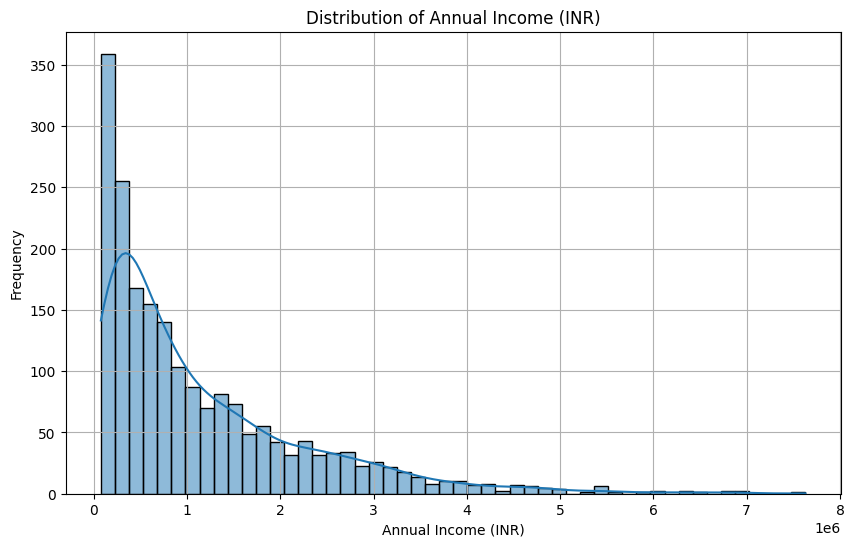

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(income_df['Annual_Income_INR'], bins=50, kde=True)
plt.title('Distribution of Annual Income (INR)')
plt.xlabel('Annual Income (INR)')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

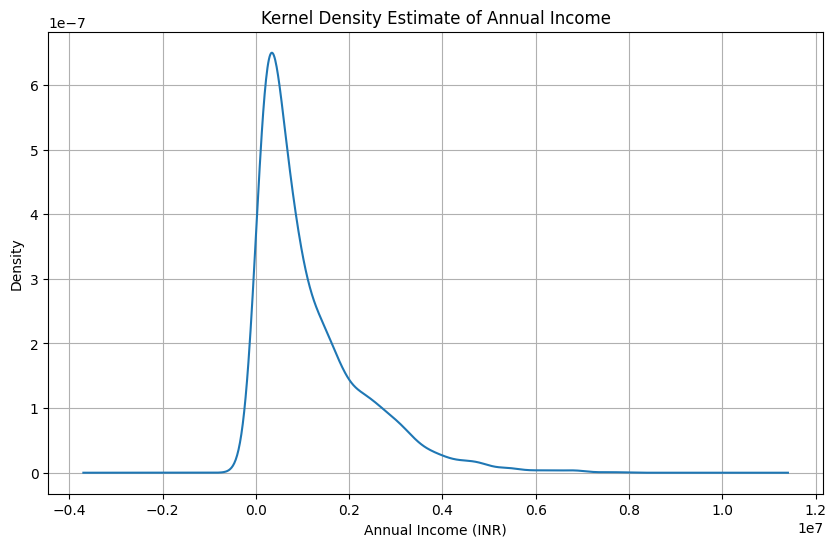

In [10]:
import matplotlib.pyplot as plt

ax = income_df['Annual_Income_INR'].plot(kind='kde', figsize=(10, 6))
ax.set_xlabel('Annual Income (INR)')
ax.set_ylabel('Density')
ax.set_title('Kernel Density Estimate of Annual Income')
plt.grid(True)
plt.show()

In [20]:
#sample size=70 -->200 time
sample_year=[]
for i in range(200):
  sample_year.append(income_df['Annual_Income_INR'].sample(100).values.tolist())

In [21]:
sample_year=np.array(sample_year)

In [22]:
sample_year_means=sample_year.mean(axis=1)

In [23]:
len(sample_year_means)

200

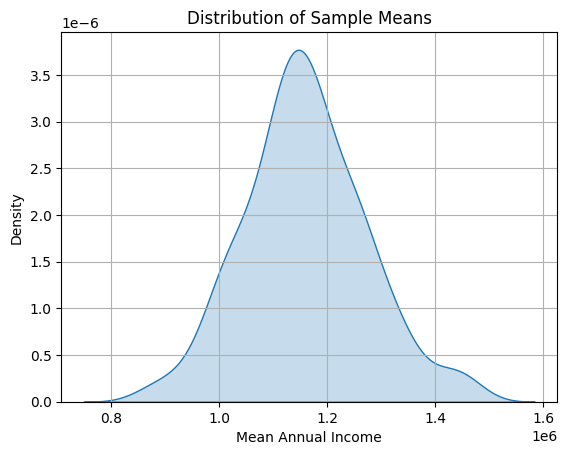

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.kdeplot(sample_year_means, fill=True)
plt.xlabel('Mean Annual Income')
plt.ylabel('Density')
plt.title('Distribution of Sample Means')
plt.grid(True)
plt.show()

In [25]:
sample_year_means.mean()

np.float64(1159531.56)

In [26]:
mean_of_sample_means = sample_year_means.mean()
std_dev_of_sample_means = sample_year_means.std()

# For a 95% confidence interval, the z-score is approximately 1.96
z_score = 1.96

# Calculate the standard error of the mean of the sample means
# In this case, since sample_year_means already represents the means of samples,
# its standard deviation is an estimate of the standard error of the mean.
# However, if we were to calculate the standard error of a single mean from the population
# using sample_year_means as a sample of means, we would divide by sqrt(n).
# But here, we are looking for the confidence interval of the *distribution of sample means* itself.
# Let's consider the variability of the `sample_year_means` as the relevant standard error.

# If we consider sample_year_means as a set of observed sample means,
# and we want to find the confidence interval for the *true mean of the population of sample means* (which should be close to the population mean).
# The standard error of this distribution of sample means is its standard deviation.

# Standard error for the mean of the sample means
standard_error_of_mean = std_dev_of_sample_means / np.sqrt(len(sample_year_means))

# Lower and Upper bounds
lower_limit = mean_of_sample_means - (z_score * std_dev_of_sample_means)
upper_limit = mean_of_sample_means + (z_score * std_dev_of_sample_means)

print(f"Mean of sample means: {mean_of_sample_means:.2f}")
print(f"Standard deviation of sample means: {std_dev_of_sample_means:.2f}")
print(f"Lower limit (95% CI): {lower_limit:.2f}")
print(f"Upper limit (95% CI): {upper_limit:.2f}")

Mean of sample means: 1159531.56
Standard deviation of sample means: 112106.86
Lower limit (95% CI): 939802.11
Upper limit (95% CI): 1379261.01


In [27]:
# Similar analysis for Monthly Income
sample_month = []
for i in range(200):
  sample_month.append(income_df['Monthly_Income_INR'].sample(100).values.tolist())

In [28]:
sample_month = np.array(sample_month)

In [32]:
sample_month_means = sample_month.mean(axis=1)

In [31]:
mean_of_sample_month_means = sample_month_means.mean()
std_dev_of_sample_month_means = sample_month_means.std()

# For a 95% confidence interval, the z-score is approximately 1.96
z_score = 1.96

# Lower and Upper bounds for monthly income
lower_limit_month = mean_of_sample_month_means - (z_score * std_dev_of_sample_month_means)
upper_limit_month = mean_of_sample_month_means + (z_score * std_dev_of_sample_month_means)

print(f"Mean of sample monthly means: {mean_of_sample_month_means:.2f}")
print(f"Standard deviation of sample monthly means: {std_dev_of_sample_month_means:.2f}")
print(f"Lower limit (95% CI) for Monthly Income: {lower_limit_month:.2f}")
print(f"Upper limit (95% CI) for Monthly Income: {upper_limit_month:.2f}")

Mean of sample monthly means: 96759.55
Standard deviation of sample monthly means: 8823.64
Lower limit (95% CI) for Monthly Income: 79465.22
Upper limit (95% CI) for Monthly Income: 114053.89
